## Part 1: Import the required libraries



In [ ]:
!pip -q install ultralytics torchmetrics pycocotools torchinfo

In [ ]:
import os, glob, json, random, shutil, zipfile, time, copy, math
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import torch, torch.nn as nn, torch.nn.functional as F
from torchvision.ops import box_iou, batched_nms
from torchmetrics.detection import MeanAveragePrecision

SEED = 42
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "| torch", torch.__version__)
if device == "cpu":
    print("WARNING: no GPU. Training will be very slow. Runtime > Change runtime type > T4 GPU")

Device: cuda | torch 2.14.1+cu130


## Part 2: Upload and unzip your dataset


In [ ]:
USE_DRIVE  = False
DRIVE_PATH = "/content/150 data set.v1i.voc.zip"
ZIP_NAME   = "150_data_set_v1i_voc.zip"
DATA_ROOT  = Path("/content/dataset")

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP_PATH = DRIVE_PATH
else:

    alt_zip_name = "150 data set.v1i.voc.zip"
    if Path(alt_zip_name).exists():
        ZIP_PATH = alt_zip_name
    elif Path(ZIP_NAME).exists():
        ZIP_PATH = ZIP_NAME
    else:
        from google.colab import files
        uploaded = files.upload()
        ZIP_PATH = list(uploaded.keys())[0] if uploaded else ZIP_NAME

DATA_ROOT.mkdir(exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA_ROOT)

for s in ["train", "valid", "test"]:
    print(f"{s:6s}: {len(list((DATA_ROOT/s).glob('*.jpg')))} images, {len(list((DATA_ROOT/s).glob('*.xml')))} xml files")

train : 175 images, 175 xml files
valid : 49 images, 49 xml files
test  : 10 images, 10 xml files


## Part 3: Read the VOC annotations and inspect the data



In [ ]:
CLASSES = ["Book", "Bottle", "Plate"]
C = len(CLASSES)
cls2id = {c: i for i, c in enumerate(CLASSES)}
IMG = 416

def read_voc(img_path):
    """Return (PIL image, boxes xyxy in pixels of that image, labels, was_rotated)."""
    root = ET.parse(img_path.with_suffix(".xml")).getroot()
    xw = int(root.find("size/width").text); xh = int(root.find("size/height").text)
    im = Image.open(img_path).convert("RGB")
    rotated = False
    if im.size == (xh, xw) and xw != xh:                  # fix 1: portrait/landscape mismatch
        im = im.transpose(Image.Transpose.ROTATE_90); rotated = True
    W, H = im.size
    boxes, labels = [], []
    for o in root.findall("object"):
        b = o.find("bndbox")
        x1, y1, x2, y2 = [float(b.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")]
        x1, x2 = np.clip([x1, x2], 0, W); y1, y2 = np.clip([y1, y2], 0, H)   # fix 2: clip
        if x2 - x1 < 1 or y2 - y1 < 1: continue                              # fix 3: drop degenerate
        boxes.append([x1, y1, x2, y2]); labels.append(cls2id[o.find("name").text])
    return im, np.array(boxes, np.float32).reshape(-1, 4), np.array(labels, np.int64), rotated

def build_cache(split):
    paths = sorted((DATA_ROOT / split).glob("*.jpg"))
    imgs = np.zeros((len(paths), IMG, IMG, 3), np.uint8)
    boxes, labels, names, nrot = [], [], [], 0
    for i, p in enumerate(paths):
        im, b, l, rot = read_voc(p); nrot += rot
        W, H = im.size
        imgs[i] = np.asarray(im.resize((IMG, IMG), Image.BILINEAR))
        b = b * np.array([IMG / W, IMG / H, IMG / W, IMG / H], np.float32)   # to 416-px coordinates
        keep = ((b[:, 2] - b[:, 0]) >= 2) & ((b[:, 3] - b[:, 1]) >= 2)      # drop boxes <2px after resize
        boxes.append(b[keep]); labels.append(l[keep]); names.append(p.name)
    print(f"{split:6s}: {len(paths)} images, {sum(len(b) for b in boxes)} boxes, "
          f"{sum(len(b) == 0 for b in boxes)} empty images, {nrot} images rotated")
    return dict(imgs=imgs, boxes=boxes, labels=labels, names=names)

DATA = {s: build_cache(s) for s in ["train", "valid", "test"]}

train : 175 images, 304 boxes, 0 empty images, 20 images rotated
valid : 49 images, 62 boxes, 4 empty images, 15 images rotated
test  : 10 images, 9 boxes, 1 empty images, 1 images rotated


,images,Book,Bottle,Plate
split,,,,
train,175,113,49,142
valid,49,15,19,28
test,10,1,3,5


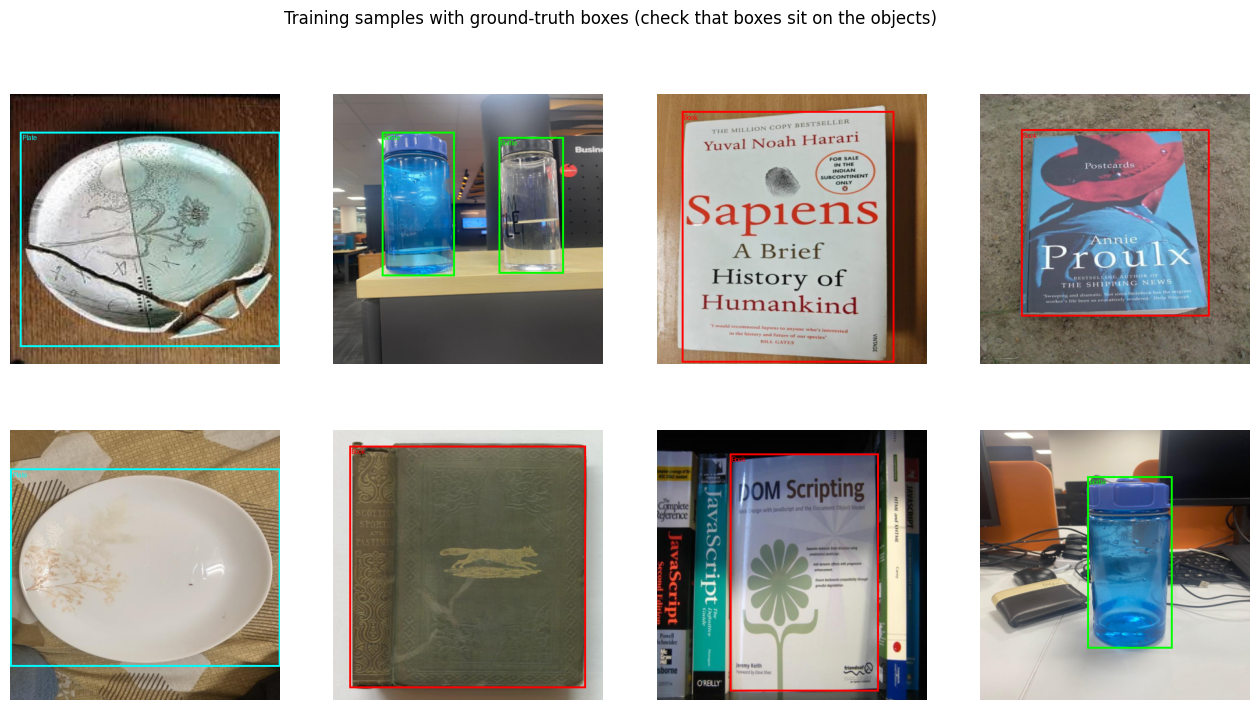

In [ ]:

rows = []
for s in DATA:
    cnt = np.bincount(np.concatenate(DATA[s]["labels"]) if len(DATA[s]["labels"]) else [], minlength=C)
    rows.append(dict(split=s, images=len(DATA[s]["imgs"]), **{c: int(n) for c, n in zip(CLASSES, cnt)}))
display(pd.DataFrame(rows).set_index("split"))

def draw_boxes(img_arr, boxes, labels, scores=None):
    im = Image.fromarray(img_arr).copy(); d = ImageDraw.Draw(im)
    colors = ["red", "lime", "cyan"]
    for k, (b, l) in enumerate(zip(boxes, labels)):
        col = colors[int(l) % 3]
        d.rectangle([float(v) for v in b], outline=col, width=3)
        d.text((float(b[0]) + 3, float(b[1]) + 3), CLASSES[int(l)] + (f" {scores[k]:.2f}" if scores is not None else ""), fill=col)
    return im

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.ravel(), np.random.RandomState(0).choice(len(DATA["train"]["imgs"]), 8, replace=False)):
    d = DATA["train"]; ax.imshow(draw_boxes(d["imgs"][i], d["boxes"][i], d["labels"][i])); ax.axis("off")
plt.suptitle("Training samples with ground-truth boxes (check that boxes sit on the objects)"); plt.show()

## Part 4: Your Keras YOLO code converted to PyTorch





In [ ]:
# -------------------translation of your Keras code -------------------------------------------
class YOLOBackboneTorch(nn.Module):
    def __init__(self):
        super().__init__()
        chans = [3, 32, 64, 128, 256, 512]
        layers = []
        for i in range(5):
            layers += [nn.Conv2d(chans[i], chans[i + 1], kernel_size=3, stride=1, padding=1),
                       nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
        self.features = nn.Sequential(*layers)
    def forward(self, x):
        return self.features(x)

class YOLOHeadTorch(nn.Module):
    def __init__(self, in_ch, num_classes, num_boxes):
        super().__init__()
        self.num_boxes, self.num_classes = num_boxes, num_classes
        # 5 = x, y, w, h, confidence
        self.conv = nn.Conv2d(in_ch, num_boxes * (num_classes + 5), kernel_size=1)
    def forward(self, x):
        x = self.conv(x)
        N, _, H, W = x.shape
        x = x.permute(0, 2, 3, 1)
        return x.reshape(N, H, W, self.num_boxes, self.num_classes + 5)

class YOLOModelTorch(nn.Module):
    def __init__(self, num_classes=20, num_boxes=3):
        super().__init__()
        self.backbone = YOLOBackboneTorch()
        self.head = YOLOHeadTorch(512, num_classes, num_boxes)
    def forward(self, x):
        return self.head(self.backbone(x))

# Step 4 in your code: dummy test
from torchinfo import summary
yolo_torch = YOLOModelTorch(num_classes=20, num_boxes=3).to(device)
print(summary(yolo_torch, input_size=(1, 3, 416, 416), device=device, verbose=0))

dummy_input = torch.rand(1, 3, 416, 416).to(device)
yolo_torch.eval()
with torch.no_grad():
    yolo_pred = yolo_torch(dummy_input)
print("YOLO Prediction Shape:", tuple(yolo_pred.shape))

Layer (type:depth-idx)                   Output Shape              Param #
YOLOModelTorch                           [1, 13, 13, 3, 25]        --
├─YOLOBackboneTorch: 1-1                 [1, 512, 13, 13]          --
│    └─Sequential: 2-1                   [1, 512, 13, 13]          --
│    │    └─Conv2d: 3-1                  [1, 32, 416, 416]         896
│    │    └─ReLU: 3-2                    [1, 32, 416, 416]         --
│    │    └─MaxPool2d: 3-3               [1, 32, 208, 208]         --
│    │    └─Conv2d: 3-4                  [1, 64, 208, 208]         18,496
│    │    └─ReLU: 3-5                    [1, 64, 208, 208]         --
│    │    └─MaxPool2d: 3-6               [1, 64, 104, 104]         --
│    │    └─Conv2d: 3-7                  [1, 128, 104, 104]        73,856
│    │    └─ReLU: 3-8                    [1, 128, 104, 104]        --
│    │    └─MaxPool2d: 3-9               [1, 128, 52, 52]          --
│    │    └─Conv2d: 3-10                 [1, 256, 52, 52]          295,168
│

## Part 5: Train the developed model on your data, then improve it by adding / removing layers



In [ ]:
def kmeans_anchors(wh, k=3, iters=200, seed=0):
    rng = np.random.RandomState(seed)
    cent = wh[rng.choice(len(wh), k, replace=False)]
    def iou(wh, c):
        inter = np.minimum(wh[:, None, 0], c[None, :, 0]) * np.minimum(wh[:, None, 1], c[None, :, 1])
        return inter / (wh[:, None, 0] * wh[:, None, 1] + c[None, :, 0] * c[None, :, 1] - inter)
    for _ in range(iters):
        a = iou(wh, cent).argmax(1)
        new = np.array([np.median(wh[a == j], 0) if (a == j).any() else cent[j] for j in range(k)])
        if np.allclose(new, cent): break
        cent = new
    return cent[np.argsort(cent.prod(1))].astype(np.float32)

wh = np.concatenate([(b[:, 2:] - b[:, :2]) / IMG for b in DATA["train"]["boxes"] if len(b)])
ANCHORS = kmeans_anchors(wh, k=3)
ANCHORS_T = torch.tensor(ANCHORS, device=device)
print("Anchors (w, h as fraction of image):\n", ANCHORS.round(3))

Anchors (w, h as fraction of image):
 [[0.184 0.314]
 [0.387 0.428]
 [0.838 0.748]]


### Step 6: Four model variants (adding and removing layers)





In [ ]:
def conv_block(cin, cout, k=3, bn=True):
    layers = [nn.Conv2d(cin, cout, k, padding=k // 2, bias=not bn)]
    layers += [nn.BatchNorm2d(cout), nn.LeakyReLU(0.1, inplace=True)] if bn else [nn.ReLU(inplace=True)]
    return layers

VARIANTS = {
    "A_baseline":  dict(stages=[(32,1),(64,1),(128,1),(256,1),(512,1)], bn=False, neck=False, lr=3e-4),
    "B_bn_leaky":  dict(stages=[(32,1),(64,1),(128,1),(256,1),(512,1)], bn=True,  neck=False, lr=1e-3),
    "C_deeper":    dict(stages=[(32,1),(64,1),(128,2),(256,2),(512,2)], bn=True,  neck=True,  lr=1e-3),
    "D_shallower": dict(stages=[(32,1),(64,1),(128,1),(256,1)],         bn=True,  neck=False, lr=1e-3),
}   # stages = (out_channels, number_of_convs) ; every stage ends with a 2x2 max-pool

class YOLONet(nn.Module):
    def __init__(self, cfg, num_classes, num_anchors):
        super().__init__()
        layers, cin = [], 3
        for cout, n in cfg["stages"]:
            for _ in range(n):
                layers += conv_block(cin, cout, 3, cfg["bn"]); cin = cout
            layers.append(nn.MaxPool2d(2))
        if cfg["neck"]:
            layers += conv_block(cin, 1024, 3) + conv_block(1024, 512, 1) + conv_block(512, 1024, 3); cin = 1024
        self.backbone = nn.Sequential(*layers)
        self.head = nn.Conv2d(cin, num_anchors * (5 + num_classes), 1)
        self.A, self.C = num_anchors, num_classes
        with torch.no_grad():                           # start with "no object" everywhere
            self.head.bias.view(num_anchors, 5 + num_classes)[:, 4] = -4.0
    def forward(self, x):                               # -> (N, S, S, A, 5+C), same layout as your Keras output
        x = self.head(self.backbone(x))
        N, _, S, _ = x.shape
        return x.view(N, self.A, 5 + self.C, S, S).permute(0, 3, 4, 1, 2).contiguous()

for name, cfg in VARIANTS.items():
    m = YOLONet(cfg, C, 3)
    out = m(torch.rand(1, 3, IMG, IMG))
    print(f"{name:12s} params={sum(p.numel() for p in m.parameters())/1e6:5.2f}M  output={tuple(out.shape)}")

A_baseline   params= 1.58M  output=(1, 13, 13, 3, 8)
B_bn_leaky   params= 1.58M  output=(1, 13, 13, 3, 8)
C_deeper     params=14.66M  output=(1, 13, 13, 3, 8)
D_shallower  params= 0.40M  output=(1, 26, 26, 3, 8)


### Step 7: Dataset with light augmentation


In [ ]:
class DetDataset(torch.utils.data.Dataset):
    def __init__(self, split, augment=False):
        self.d, self.aug = DATA[split], augment
    def __len__(self): return len(self.d["imgs"])
    def __getitem__(self, i):
        img = torch.from_numpy(self.d["imgs"][i]).permute(2, 0, 1).float() / 255
        boxes = torch.from_numpy(self.d["boxes"][i]).clone()
        labels = torch.from_numpy(self.d["labels"][i]).clone()
        if self.aug:
            if random.random() < 0.5:
                img = img.flip(-1); boxes[:, [0, 2]] = IMG - boxes[:, [2, 0]]
            if random.random() < 0.5:
                img = img.flip(-2); boxes[:, [1, 3]] = IMG - boxes[:, [3, 1]]
            img = (img * random.uniform(0.7, 1.3) + random.uniform(-0.1, 0.1)).clamp(0, 1)
        return img, boxes, labels

def collate(batch):
    imgs, boxes, labels = zip(*batch)
    return torch.stack(imgs), list(boxes), list(labels)

### Step 8: Targets, loss, decoding and the mAP metric


In [ ]:
def decode_boxes(pred, anchors):
    """raw output (B,S,S,A,5+C) -> normalised xyxy boxes (B,S,S,A,4)"""
    B, S, _, A, _ = pred.shape
    gy, gx = torch.meshgrid(torch.arange(S, device=pred.device), torch.arange(S, device=pred.device), indexing="ij")
    gx = gx[None, :, :, None].float(); gy = gy[None, :, :, None].float()
    cx = (torch.sigmoid(pred[..., 0]) + gx) / S
    cy = (torch.sigmoid(pred[..., 1]) + gy) / S
    w = anchors[:, 0] * torch.exp(pred[..., 2].clamp(-6, 4))
    h = anchors[:, 1] * torch.exp(pred[..., 3].clamp(-6, 4))
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)

def build_targets(boxes_list, labels_list, S, anchors):
    B, A = len(boxes_list), anchors.shape[0]
    anc = anchors.detach().cpu().numpy()
    obj = torch.zeros(B, S, S, A, dtype=torch.bool)
    txy = torch.zeros(B, S, S, A, 2); twh = torch.zeros(B, S, S, A, 2)
    tcls = torch.zeros(B, S, S, A, dtype=torch.long)
    for b, (bx, lb) in enumerate(zip(boxes_list, labels_list)):
        bx = bx.cpu().numpy() / IMG
        for k in range(len(bx)):
            x1, y1, x2, y2 = bx[k]; w, h = x2 - x1, y2 - y1; cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
            gi, gj = min(int(cx * S), S - 1), min(int(cy * S), S - 1)
            inter = np.minimum(anc[:, 0], w) * np.minimum(anc[:, 1], h)
            a = int((inter / (anc[:, 0] * anc[:, 1] + w * h - inter)).argmax())
            obj[b, gj, gi, a] = True
            txy[b, gj, gi, a] = torch.tensor([cx * S - gi, cy * S - gj])
            twh[b, gj, gi, a] = torch.tensor([math.log(w / anc[a, 0] + 1e-9), math.log(h / anc[a, 1] + 1e-9)])
            tcls[b, gj, gi, a] = int(lb[k])
    return obj, txy, twh, tcls

def yolo_loss(pred, boxes_list, labels_list, anchors, l_coord=5.0, l_noobj=0.5, ignore_thr=0.5):
    B, S, _, A, _ = pred.shape
    obj, txy, twh, tcls = [t.to(pred.device) for t in build_targets(boxes_list, labels_list, S, anchors)]
    with torch.no_grad():                                         # ignore negatives that already fit an object
        pb = decode_boxes(pred, anchors).reshape(B, -1, 4)
        ignore = torch.zeros(B, S * S * A, dtype=torch.bool, device=pred.device)
        for b in range(B):
            if len(boxes_list[b]):
                ignore[b] = box_iou(pb[b], boxes_list[b].to(pred.device) / IMG).max(1).values > ignore_thr
        ignore = ignore.view(B, S, S, A)
    pobj = pred[..., 4]
    neg = (~obj) & (~ignore)
    l_obj = F.binary_cross_entropy_with_logits(pobj[obj], torch.ones_like(pobj[obj]), reduction="sum")
    l_no = F.binary_cross_entropy_with_logits(pobj[neg], torch.zeros_like(pobj[neg]), reduction="sum")
    if obj.any():
        p = pred[obj]
        l_xy = F.mse_loss(torch.sigmoid(p[:, 0:2]), txy[obj], reduction="sum")
        l_wh = F.mse_loss(p[:, 2:4], twh[obj], reduction="sum")
        l_cls = F.cross_entropy(p[:, 5:], tcls[obj], reduction="sum")
    else:
        l_xy = l_wh = l_cls = pred.sum() * 0
    return (l_coord * (l_xy + l_wh) + l_obj + l_noobj * l_no + l_cls) / B

@torch.no_grad()
def postprocess(pred, anchors, conf_thr=0.01, nms_thr=0.5, max_det=100):
    B = pred.shape[0]
    boxes = decode_boxes(pred, anchors).reshape(B, -1, 4) * IMG
    obj = torch.sigmoid(pred[..., 4]).reshape(B, -1)
    cls = torch.softmax(pred[..., 5:], -1).reshape(B, -1, pred.shape[-1] - 5)
    out = []
    for b in range(B):
        sc = obj[b][:, None] * cls[b]                              # (cells*anchors, C)
        idx, c = (sc > conf_thr).nonzero(as_tuple=True)
        bx, s = boxes[b][idx].clamp(0, IMG), sc[idx, c]
        keep = batched_nms(bx, s, c, nms_thr)[:max_det]
        out.append(dict(boxes=bx[keep].cpu(), scores=s[keep].cpu(), labels=c[keep].cpu()))
    return out

def compute_map(preds, split):
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", class_metrics=True)
    d = DATA[split]
    targets = [dict(boxes=torch.from_numpy(b).float(), labels=torch.from_numpy(l)) for b, l in zip(d["boxes"], d["labels"])]
    metric.update(preds, targets); r = metric.compute()
    per_class = {}
    try:
        pc = torch.atleast_1d(r["map_per_class"]).tolist(); cl = torch.atleast_1d(r["classes"]).tolist()
        per_class = {CLASSES[c]: round(v, 3) for c, v in zip(cl, pc)}
    except Exception: pass
    return dict(mAP50=float(r["map_50"]), mAP=float(r["map"]), per_class=per_class)

@torch.no_grad()
def predict_custom(model, split, bs=16):
    model.eval(); d = DATA[split]; out = []
    for i in range(0, len(d["imgs"]), bs):
        x = torch.from_numpy(d["imgs"][i:i + bs]).permute(0, 3, 1, 2).float().div(255).to(device)
        out += postprocess(model(x), ANCHORS_T)
    return out

### Step 9: Train all four variants


In [ ]:
EPOCHS_CUSTOM = 100

def train_custom(name, cfg, epochs=EPOCHS_CUSTOM, bs=16):
    seed_everything()
    model = YOLONet(cfg, C, len(ANCHORS)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: min(1, (e + 1) / 5) * 0.5 * (1 + math.cos(math.pi * e / epochs)))
    loader = torch.utils.data.DataLoader(DetDataset("train", True), batch_size=bs, shuffle=True, collate_fn=collate)
    best, best_state, hist = -1, None, dict(epoch=[], loss=[], val_epoch=[], val_map50=[])
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot = 0
        for x, boxes, labels in loader:
            x = x.to(device)
            loss = yolo_loss(model(x), boxes, labels, ANCHORS_T)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            opt.step(); tot += loss.item() * len(x)
        sched.step()
        hist["epoch"].append(ep); hist["loss"].append(tot / len(loader.dataset))
        if ep % 5 == 0 or ep == epochs:
            m = compute_map(predict_custom(model, "valid"), "valid")["mAP50"]
            hist["val_epoch"].append(ep); hist["val_map50"].append(m)
            if m > best: best, best_state = m, copy.deepcopy(model.state_dict())
            print(f"[{name}] epoch {ep:3d}/{epochs}  loss {hist['loss'][-1]:8.3f}  val mAP50 {m:.3f}  (best {best:.3f})  {time.time()-t0:.0f}s")
    model.load_state_dict(best_state)
    return model, hist

CUSTOM_MODELS, CUSTOM_HIST = {}, {}
for name, cfg in VARIANTS.items():
    CUSTOM_MODELS[name], CUSTOM_HIST[name] = train_custom(name, cfg)

[A_baseline] epoch   5/100  loss   15.346  val mAP50 0.000  (best 0.000)  14s
[A_baseline] epoch  10/100  loss   14.697  val mAP50 0.000  (best 0.000)  24s
[A_baseline] epoch  15/100  loss   14.192  val mAP50 0.000  (best 0.000)  35s
[A_baseline] epoch  20/100  loss   13.861  val mAP50 0.016  (best 0.016)  46s
[A_baseline] epoch  25/100  loss   13.324  val mAP50 0.130  (best 0.130)  57s
[A_baseline] epoch  30/100  loss   13.271  val mAP50 0.109  (best 0.130)  67s
[A_baseline] epoch  35/100  loss   12.991  val mAP50 0.108  (best 0.130)  78s
[A_baseline] epoch  40/100  loss   12.789  val mAP50 0.111  (best 0.130)  89s
[A_baseline] epoch  45/100  loss   12.725  val mAP50 0.105  (best 0.130)  100s
[A_baseline] epoch  50/100  loss   12.457  val mAP50 0.087  (best 0.130)  111s
[A_baseline] epoch  55/100  loss   12.308  val mAP50 0.061  (best 0.130)  122s
[A_baseline] epoch  60/100  loss   12.297  val mAP50 0.100  (best 0.130)  132s
[A_baseline] epoch  65/100  loss   12.056  val mAP50 0.090  

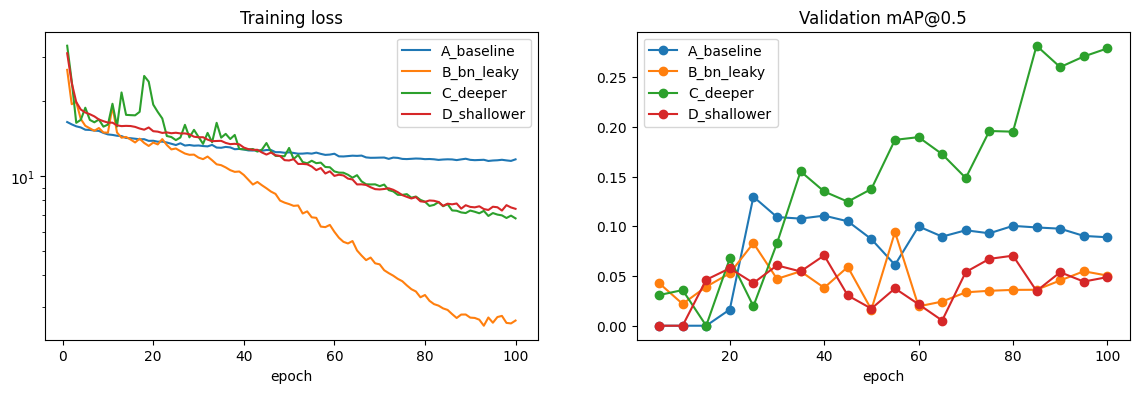

In [ ]:
# Training curves
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for n, h in CUSTOM_HIST.items():
    ax[0].plot(h["epoch"], h["loss"], label=n); ax[1].plot(h["val_epoch"], h["val_map50"], marker="o", label=n)
ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch"); ax[0].set_yscale("log"); ax[0].legend()
ax[1].set_title("Validation mAP@0.5"); ax[1].set_xlabel("epoch"); ax[1].legend(); plt.show()

### Step 10: Test every variant on valid and test


In [ ]:
RESULTS, PREDS = [], {}           # RESULTS feeds the final table; PREDS feeds the prediction pictures
def count_params(m): return sum(p.numel() for p in m.parameters())

for name, model in CUSTOM_MODELS.items():
    pv, pt = predict_custom(model, "valid"), predict_custom(model, "test")
    rv, rt = compute_map(pv, "valid"), compute_map(pt, "test")
    PREDS[name] = pt
    RESULTS.append(dict(Model=f"Custom YOLO {name}", Pretrained="no", Params_M=round(count_params(model) / 1e6, 2),
                        Val_mAP50=rv["mAP50"], Val_mAP50_95=rv["mAP"], Test_mAP50=rt["mAP50"], Test_mAP50_95=rt["mAP"]))
    print(name, "| per-class val AP:", rv["per_class"])

display(pd.DataFrame(RESULTS).round(3))

A_baseline | per-class val AP: {'Book': 0.082, 'Bottle': 0.0, 'Plate': 0.039}
B_bn_leaky | per-class val AP: {'Book': 0.06, 'Bottle': 0.014, 'Plate': 0.041}
C_deeper | per-class val AP: {'Book': 0.155, 'Bottle': 0.036, 'Plate': 0.09}
D_shallower | per-class val AP: {'Book': 0.046, 'Bottle': 0.003, 'Plate': 0.013}


,Model,Pretrained,Params_M,Val_mAP50,Val_mAP50_95,Test_mAP50,Test_mAP50_95
0,Custom YOLO A_baseline,no,1.58,0.130,0.040,0.011,0.003
1,Custom YOLO B_bn_leaky,no,1.58,0.094,0.038,0.086,0.029
2,Custom YOLO C_deeper,no,14.66,0.282,0.094,0.589,0.280
3,Custom YOLO D_shallower,no,0.40,0.071,0.021,0.005,0.002


## Part 11: Pretrained YOLO (Ultralytics YOLOv8n) fine-tuned on your data



In [ ]:
YOLO_ROOT = Path("/content/yolo_data")
if YOLO_ROOT.exists(): shutil.rmtree(YOLO_ROOT)

def export_yolo(split):
    (YOLO_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)
    for p in sorted((DATA_ROOT / split).glob("*.jpg")):
        im, b, l, _ = read_voc(p); W, H = im.size
        sc = min(1.0, 640 / max(W, H))
        if sc < 1: im = im.resize((round(W * sc), round(H * sc)), Image.BILINEAR)
        im.save(YOLO_ROOT / "images" / split / p.name, quality=95)
        lines = [f"{c} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}"
                 for (x1, y1, x2, y2), c in zip(b, l)]
        (YOLO_ROOT / "labels" / split / (p.stem + ".txt")).write_text("\n".join(lines))

for s in ["train", "valid", "test"]: export_yolo(s)

yaml_text = (f"path: {YOLO_ROOT}\ntrain: images/train\nval: images/valid\ntest: images/test\nnames:\n"
             + "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))
(YOLO_ROOT / "data.yaml").write_text(yaml_text)
print(yaml_text)
for s in ["train", "valid", "test"]:
    print(s, len(list((YOLO_ROOT/"images"/s).glob("*"))), "images,", len(list((YOLO_ROOT/"labels"/s).glob("*.txt"))), "label files")

path: /content/yolo_data
train: images/train
val: images/valid
test: images/test
names:
  0: Book
  1: Bottle
  2: Plate

train 175 images, 175 label files
valid 49 images, 49 label files
test 10 images, 10 label files


### Step 12: Fine-tune


In [ ]:
from ultralytics import YOLO

yolo = YOLO("yolov8n.pt")                         # downloads COCO-pretrained weights
yolo.train(data=str(YOLO_ROOT / "data.yaml"), epochs=60, imgsz=416, batch=16, patience=20,
           seed=SEED, project="/content/runs", name="yolov8n_custom", exist_ok=True, workers=2, plots=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d2587eae040>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

### Step 13: Look at the training results


Best weights: /content/runs/yolov8n_custom/weights/best.pt


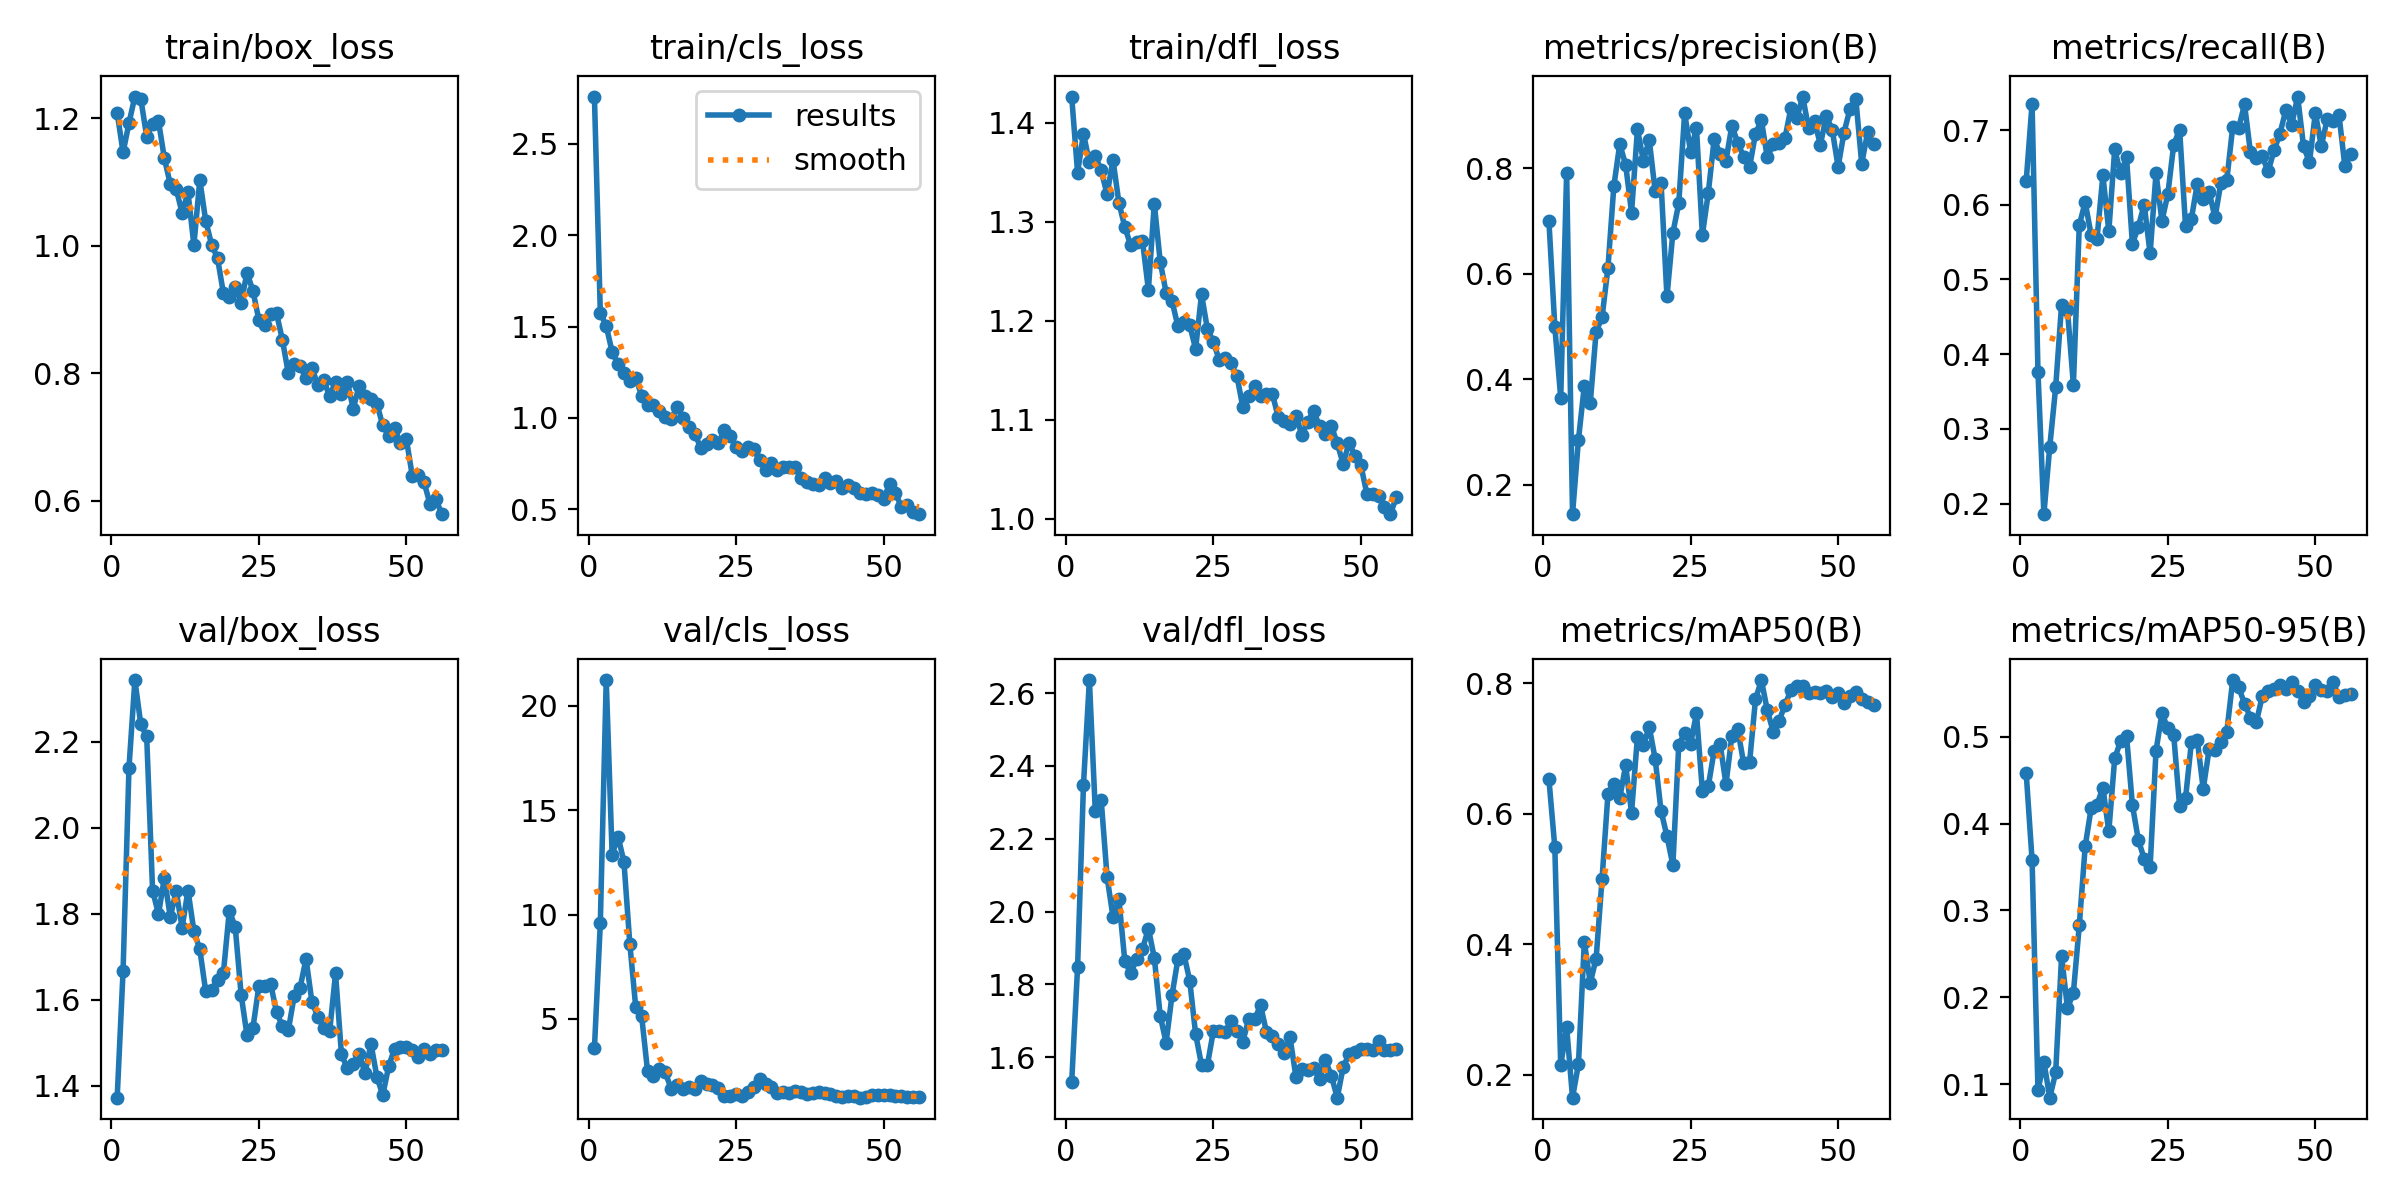

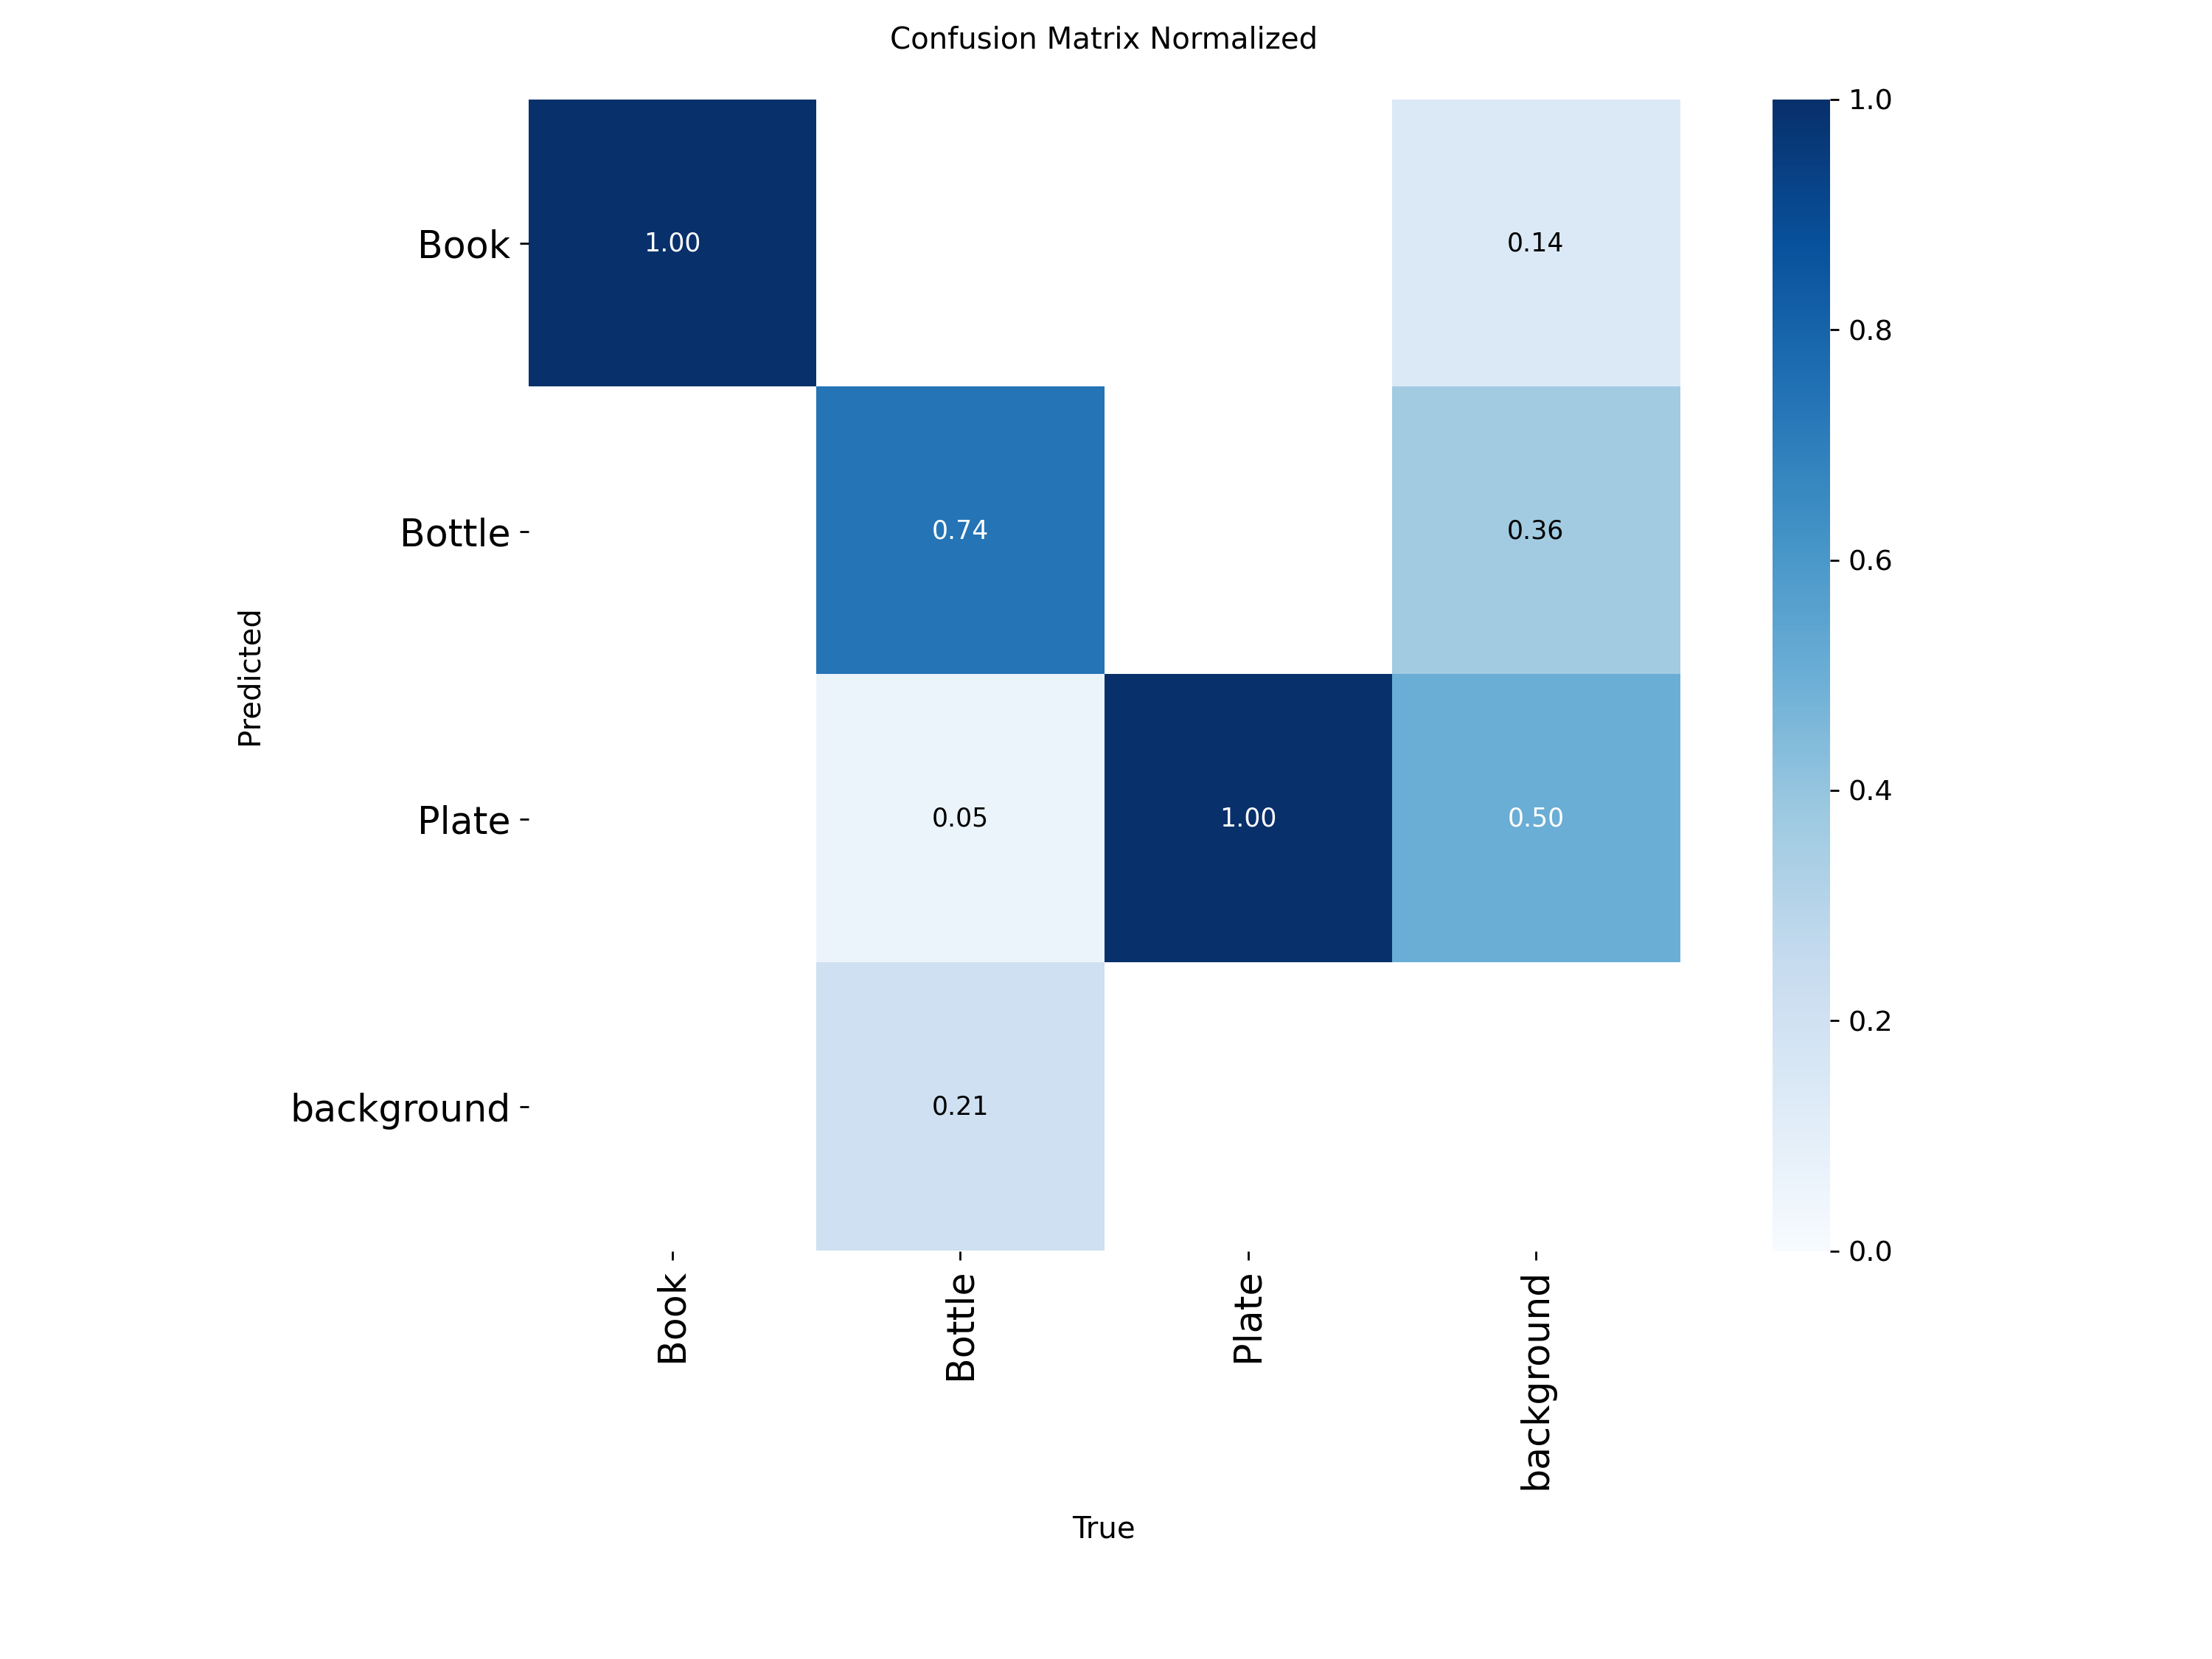

In [ ]:
from IPython.display import Image as IPImage, display as ipdisplay
SAVE = Path(yolo.trainer.save_dir)
BEST = SAVE / "weights" / "best.pt"
print("Best weights:", BEST)
ipdisplay(IPImage(str(SAVE / "results.png")))
ipdisplay(IPImage(str(SAVE / "confusion_matrix_normalized.png")))

### Step 14: Validate and test with Ultralytics' own evaluator


In [ ]:
yolo_best = YOLO(str(BEST))
for split in ["val", "test"]:
    m = yolo_best.val(data=str(YOLO_ROOT / "data.yaml"), split=split, imgsz=416, plots=False, verbose=False)
    print(f"\n=== Ultralytics {split}: precision {m.box.mp:.3f} | recall {m.box.mr:.3f} | mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")
    for i, c in enumerate(m.box.ap_class_index):
        print(f"   {CLASSES[int(c)]:7s} AP50 {m.box.ap50[i]:.3f}  AP50-95 {m.box.all_ap[i].mean():.3f}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2098.1±1091.3 MB/s, size: 86.6 KB)
val: Scanning /content/yolo_data/labels/valid.cache... 49 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 13.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 6.6it/s 0.6s
                   all         49         62      0.904       0.67      0.771      0.562
Speed: 0.4ms preprocess, 4.2ms inference, 0.0ms loss, 1.2ms postprocess per image

=== Ultralytics val: precision 0.904 | recall 0.670 | mAP50 0.771 | mAP50-95 0.562
   Book    AP50 0.874  AP50-95 0.684
   Bottle  AP50 0.549  AP50-95 0.355
   Plate   AP50 0.891  AP50-95 0.646
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 p

### Step 15: Same metric as the custom models


In [ ]:
def predict_ultra(model, split, imgsz=416):
    out = []
    for img in DATA[split]["imgs"]:
        r = model.predict(img[:, :, ::-1].copy(), imgsz=imgsz, conf=0.001, iou=0.6, verbose=False)[0]   # RGB -> BGR
        out.append(dict(boxes=r.boxes.xyxy.cpu().float(), scores=r.boxes.conf.cpu().float(), labels=r.boxes.cls.cpu().long()))
    return out

pv, pt = predict_ultra(yolo_best, "valid"), predict_ultra(yolo_best, "test")
rv, rt = compute_map(pv, "valid"), compute_map(pt, "test")
PREDS["Pretrained YOLOv8n"] = pt
RESULTS.append(dict(Model="Pretrained YOLOv8n (fine-tuned)", Pretrained="yes", Params_M=round(count_params(yolo_best.model) / 1e6, 2),
                    Val_mAP50=rv["mAP50"], Val_mAP50_95=rv["mAP"], Test_mAP50=rt["mAP50"], Test_mAP50_95=rt["mAP"]))
print("per-class val AP:", rv["per_class"])
display(pd.DataFrame(RESULTS).round(3))

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


per-class val AP: {'Book': 0.671, 'Bottle': 0.395, 'Plate': 0.575}


,Model,Pretrained,Params_M,Val_mAP50,Val_mAP50_95,Test_mAP50,Test_mAP50_95
0,Custom YOLO A_baseline,no,1.58,0.130,0.040,0.011,0.003
1,Custom YOLO B_bn_leaky,no,1.58,0.094,0.038,0.086,0.029
2,Custom YOLO C_deeper,no,14.66,0.282,0.094,0.589,0.280
3,Custom YOLO D_shallower,no,0.40,0.071,0.021,0.005,0.002
4,Pretrained YOLOv8n (fine-tuned),yes,3.14,0.723,0.547,0.817,0.679


## Part 16: Pretrained SSD (torchvision SSD300-VGG16) fine-tuned on your data



In [ ]:
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead
from torchvision.models.detection import _utils as det_utils

def build_ssd():
    m = ssd300_vgg16(weights=SSD300_VGG16_Weights.COCO_V1)                      # COCO-pretrained
    in_ch = det_utils.retrieve_out_channels(m.backbone, (300, 300))
    n_anchors = m.anchor_generator.num_anchors_per_location()
    m.head.classification_head = SSDClassificationHead(in_ch, n_anchors, num_classes=C + 1)   # +1 background
    return m

ssd = build_ssd().to(device)
print("SSD parameters: %.1fM" % (count_params(ssd) / 1e6))

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:01<00:00, 123MB/s]


SSD parameters: 24.0M


### Step 17: Train


In [ ]:
EPOCHS_SSD = 40

@torch.no_grad()
def predict_ssd(model, split, bs=8):
    model.eval(); d = DATA[split]; out = []
    for i in range(0, len(d["imgs"]), bs):
        x = [torch.from_numpy(a).permute(2, 0, 1).float().div(255).to(device) for a in d["imgs"][i:i + bs]]
        for o in model(x):
            out.append(dict(boxes=o["boxes"].cpu(), scores=o["scores"].cpu(), labels=(o["labels"] - 1).cpu()))   # back to 0..C-1
    return out

def train_ssd(model, epochs=EPOCHS_SSD, bs=8, lr=2e-3):
    seed_everything()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: min(1, (e + 1) / 3) * 0.5 * (1 + math.cos(math.pi * e / epochs)))
    loader = torch.utils.data.DataLoader(DetDataset("train", True), batch_size=bs, shuffle=True, collate_fn=collate)
    best, best_state, hist, t0 = -1, None, dict(epoch=[], loss=[], val_epoch=[], val_map50=[]), time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot = 0
        for x, boxes, labels in loader:
            imgs = [i.to(device) for i in x]
            targets = [dict(boxes=b.to(device), labels=(l + 1).to(device)) for b, l in zip(boxes, labels)]
            losses = model(imgs, targets); loss = sum(losses.values())
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 10.0)
            opt.step(); tot += loss.item() * len(imgs)
        sched.step()
        hist["epoch"].append(ep); hist["loss"].append(tot / len(loader.dataset))
        if ep % 5 == 0 or ep == epochs:
            m = compute_map(predict_ssd(model, "valid"), "valid")["mAP50"]
            hist["val_epoch"].append(ep); hist["val_map50"].append(m)
            if m > best: best, best_state = m, copy.deepcopy(model.state_dict())
            print(f"[SSD] epoch {ep:3d}/{epochs}  loss {hist['loss'][-1]:7.3f}  val mAP50 {m:.3f}  (best {best:.3f})  {time.time()-t0:.0f}s")
    model.load_state_dict(best_state)
    return model, hist

ssd, ssd_hist = train_ssd(ssd)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


[SSD] epoch   5/40  loss   2.616  val mAP50 0.798  (best 0.798)  36s
[SSD] epoch  10/40  loss   1.731  val mAP50 0.800  (best 0.800)  70s
[SSD] epoch  15/40  loss   1.216  val mAP50 0.819  (best 0.819)  105s
[SSD] epoch  20/40  loss   0.958  val mAP50 0.836  (best 0.836)  139s
[SSD] epoch  25/40  loss   0.687  val mAP50 0.829  (best 0.836)  174s
[SSD] epoch  30/40  loss   0.510  val mAP50 0.828  (best 0.836)  208s
[SSD] epoch  35/40  loss   0.473  val mAP50 0.830  (best 0.836)  242s
[SSD] epoch  40/40  loss   0.430  val mAP50 0.831  (best 0.836)  276s


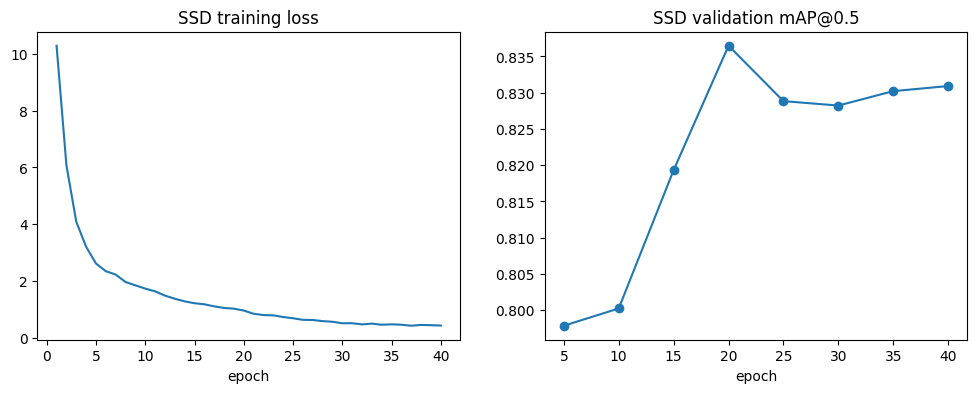

per-class val AP: {'Book': 0.734, 'Bottle': 0.36, 'Plate': 0.594}


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ssd_hist["epoch"], ssd_hist["loss"]); ax[0].set_title("SSD training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(ssd_hist["val_epoch"], ssd_hist["val_map50"], marker="o"); ax[1].set_title("SSD validation mAP@0.5"); ax[1].set_xlabel("epoch")
plt.show()

pv, pt = predict_ssd(ssd, "valid"), predict_ssd(ssd, "test")
rv, rt = compute_map(pv, "valid"), compute_map(pt, "test")
PREDS["Pretrained SSD300"] = pt
RESULTS.append(dict(Model="Pretrained SSD300-VGG16 (fine-tuned)", Pretrained="yes", Params_M=round(count_params(ssd) / 1e6, 2),
                    Val_mAP50=rv["mAP50"], Val_mAP50_95=rv["mAP"], Test_mAP50=rt["mAP50"], Test_mAP50_95=rt["mAP"]))
print("per-class val AP:", rv["per_class"])

## Part 18: Final comparison

,Model,Pretrained,Params_M,Val_mAP50,Val_mAP50_95,Test_mAP50,Test_mAP50_95
0,Custom YOLO A_baseline,no,1.58,0.130,0.040,0.011,0.003
1,Custom YOLO B_bn_leaky,no,1.58,0.094,0.038,0.086,0.029
2,Custom YOLO C_deeper,no,14.66,0.282,0.094,0.589,0.280
3,Custom YOLO D_shallower,no,0.40,0.071,0.021,0.005,0.002
4,Pretrained YOLOv8n (fine-tuned),yes,3.14,0.723,0.547,0.817,0.679
5,Pretrained SSD300-VGG16 (fine-tuned),yes,24.01,0.836,0.563,0.893,0.589


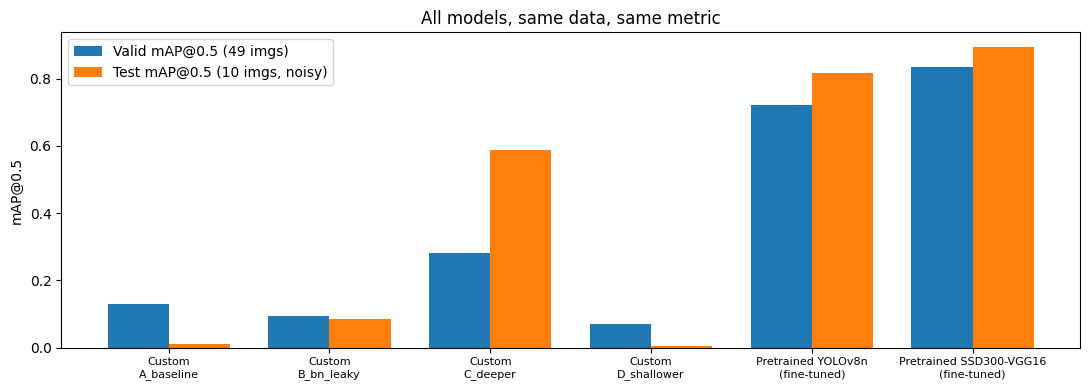

In [ ]:
df = pd.DataFrame(RESULTS).round(3)
display(df)

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(df)); w = 0.38
ax.bar(x - w / 2, df["Val_mAP50"], w, label="Valid mAP@0.5 (49 imgs)")
ax.bar(x + w / 2, df["Test_mAP50"], w, label="Test mAP@0.5 (10 imgs, noisy)")
ax.set_xticks(x); ax.set_xticklabels([m.replace(" (fine-tuned)", "\n(fine-tuned)").replace("Custom YOLO ", "Custom\n") for m in df["Model"]], fontsize=8)
ax.set_ylabel("mAP@0.5"); ax.legend(); ax.set_title("All models, same data, same metric"); plt.tight_layout(); plt.show()

### Predictions on the test images


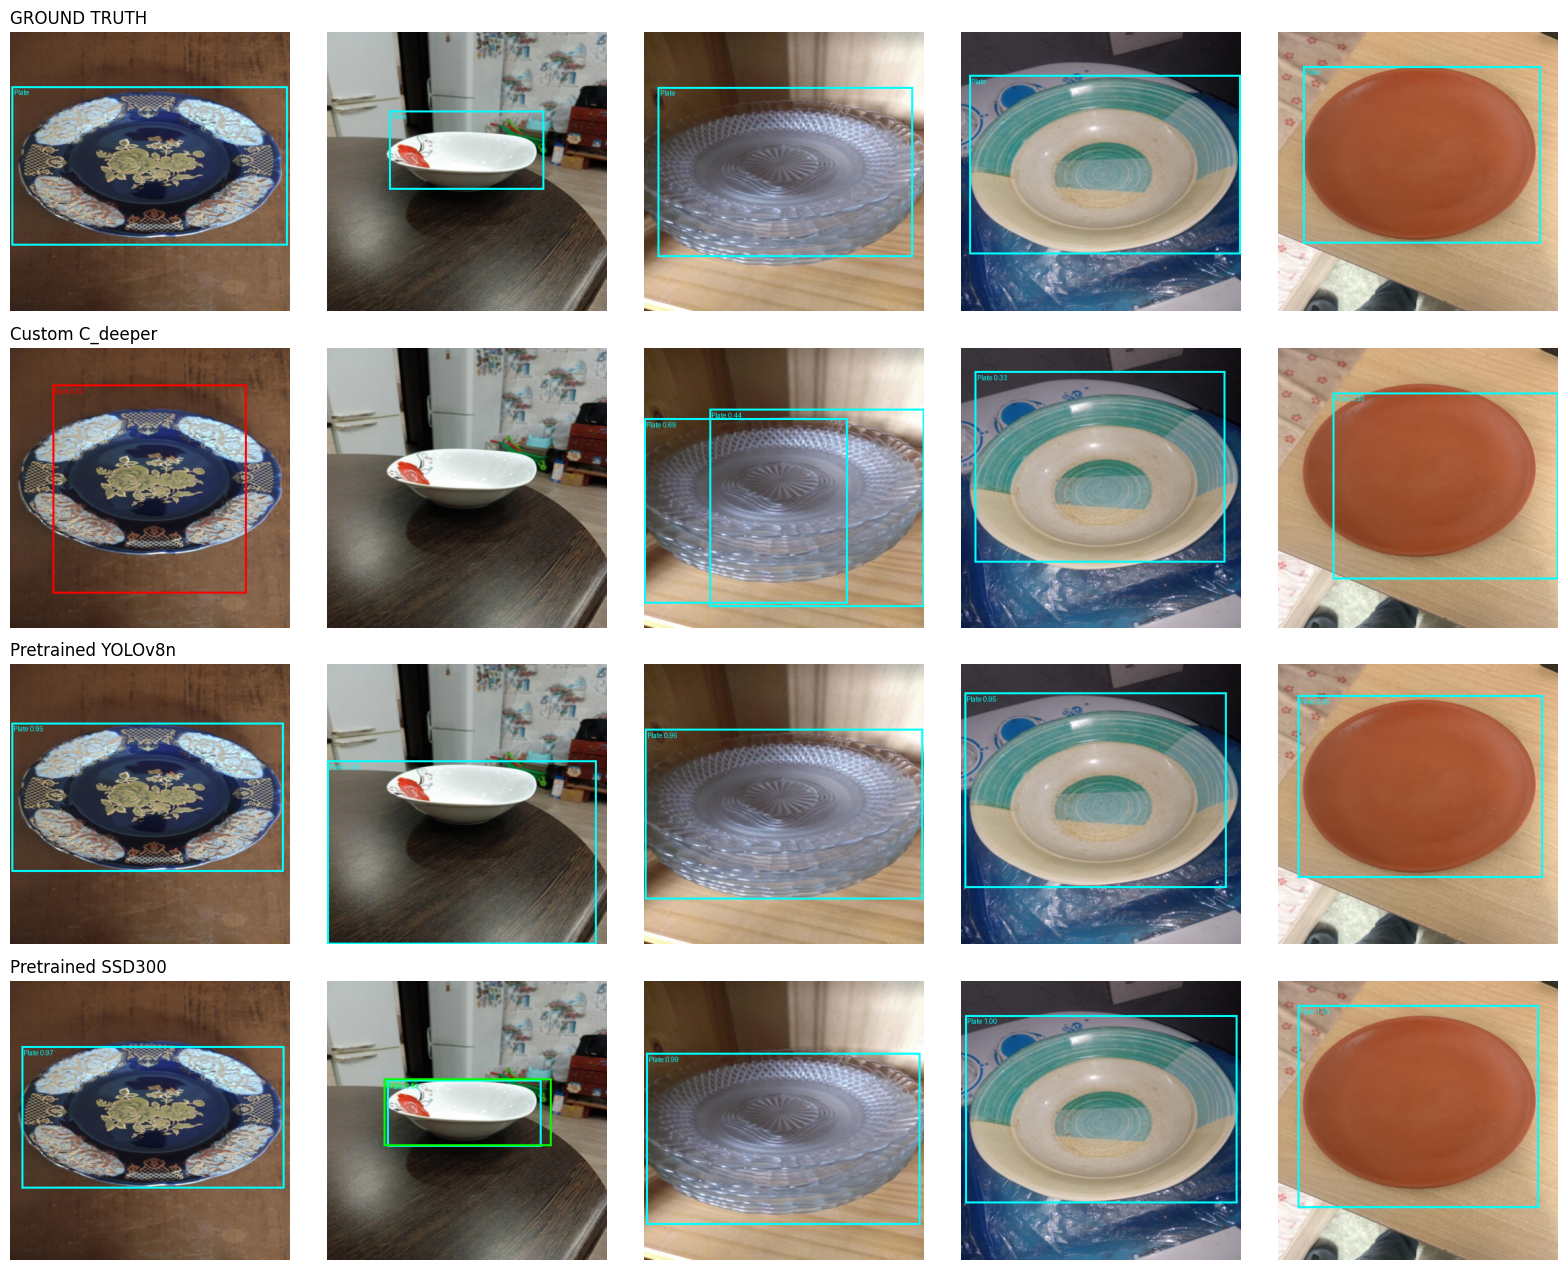

In [ ]:
best_custom = df[df["Pretrained"] == "no"].sort_values("Val_mAP50", ascending=False).iloc[0]["Model"].replace("Custom YOLO ", "")
show = {f"Custom {best_custom}": PREDS[best_custom], "Pretrained YOLOv8n": PREDS["Pretrained YOLOv8n"], "Pretrained SSD300": PREDS["Pretrained SSD300"]}

def show_grid(pred_dict, split="test", n=5, conf=0.3):
    d = DATA[split]; n = min(n, len(d["imgs"]))
    fig, axes = plt.subplots(len(pred_dict) + 1, n, figsize=(3.2 * n, 3.2 * (len(pred_dict) + 1)), squeeze=False)
    for j in range(n):
        axes[0, j].imshow(draw_boxes(d["imgs"][j], d["boxes"][j], d["labels"][j])); axes[0, j].axis("off")
        for i, (name, preds) in enumerate(pred_dict.items(), 1):
            p = preds[j]; k = p["scores"] >= conf
            axes[i, j].imshow(draw_boxes(d["imgs"][j], p["boxes"][k].numpy(), p["labels"][k].numpy(), p["scores"][k].numpy())); axes[i, j].axis("off")
    axes[0, 0].set_title("GROUND TRUTH", loc="left")
    for i, name in enumerate(pred_dict, 1): axes[i, 0].set_title(name, loc="left")
    plt.tight_layout(); plt.show()

show_grid(show, "test", n=5, conf=0.3)